# Quantum Machine Learning untuk Cybersecurity
## Demo dengan Dataset HQC-2026 (3 File Parquet)

**Dataset**: A Hybrid Quantum-Classical Network Intrusion Detection Dataset

**Tujuan**: Deteksi intrusi jaringan menggunakan Variational Quantum Classifier (VQC)

**Pipeline**:
1. Load 3 file Parquet
2. Eksplorasi & preprocessing
3. Reduksi dimensi (PCA) — 96 fitur → 4 qubit
4. Training VQC
5. Evaluasi

In [1]:
import os
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Qiskit
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms import VQC

print("✅ Semua library berhasil di-import")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")

✅ Semua library berhasil di-import
NumPy: 1.26.4
Pandas: 2.2.2


In [2]:
# ============================================
# KONFIGURASI PATH
# ============================================
DATA_DIR = "data"  # folder berisi 3 file parquet

# Cek file yang tersedia
parquet_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.parquet")))

print(f"📁 Direktori: {os.path.abspath(DATA_DIR)}")
print(f"📦 Ditemukan {len(parquet_files)} file Parquet:")
for f in parquet_files:
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"   - {os.path.basename(f):40s} ({size_mb:.2f} MB)")

if len(parquet_files) == 0:
    raise FileNotFoundError(
        f"Tidak ada file .parquet di folder '{DATA_DIR}'.\n"
        f"Letakkan 3 file Parquet HQC-2026 di folder tersebut."
    )

📁 Direktori: C:\Users\Aras\Desktop\pr\QuanML\data
📦 Ditemukan 3 file Parquet:
   - HQC20_Super_Enriched_Dataset_v4.parquet  (100.78 MB)
   - SUPER_ENRICHED_hybrid_dataset_v3.parquet (96.20 MB)
   - final_hybrid_cybersecurity_dataset.parquet (89.66 MB)


In [3]:
# ============================================
# LOAD & GABUNGKAN 3 FILE PARQUET
# ============================================
def load_parquet_files(file_list, sample_frac=0.01, random_state=42):
    """
    Memuat dan menggabungkan beberapa file Parquet.
    
    Args:
        file_list: list path file parquet
        sample_frac: fraksi sampling (0.01 = 1%) untuk efisiensi simulasi
        random_state: seed untuk reproducibility
    
    Returns:
        df: DataFrame gabungan
    """
    dfs = []
    for i, file in enumerate(file_list, 1):
        print(f"[{i}/{len(file_list)}] Memuat: {os.path.basename(file)}")
        df_part = pd.read_parquet(file, engine='pyarrow')
        print(f"    → Shape asli: {df_part.shape}")
        
        # Sampling untuk efisiensi (HQC-2026 sangat besar)
        if sample_frac < 1.0:
            n_sample = max(int(len(df_part) * sample_frac), 100)
            df_part = df_part.sample(n=n_sample, random_state=random_state)
            print(f"    → Setelah sampling {sample_frac*100:.1f}%: {df_part.shape}")
        
        dfs.append(df_part)
    
    df = pd.concat(dfs, ignore_index=True)
    print(f"\n✅ Total data gabungan: {df.shape}")
    return df

# Load data
df = load_parquet_files(parquet_files, sample_frac=0.01)

# Tampilkan 5 baris pertama
print("\n📋 Preview data:")
df.head()

[1/3] Memuat: HQC20_Super_Enriched_Dataset_v4.parquet
    → Shape asli: (233844, 104)
    → Setelah sampling 1.0%: (2338, 104)
[2/3] Memuat: SUPER_ENRICHED_hybrid_dataset_v3.parquet
    → Shape asli: (233844, 96)
    → Setelah sampling 1.0%: (2338, 96)
[3/3] Memuat: final_hybrid_cybersecurity_dataset.parquet
    → Shape asli: (233844, 88)
    → Setelah sampling 1.0%: (2338, 88)

✅ Total data gabungan: (7014, 104)

📋 Preview data:


,dst_port,protocol,flow_duration,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,...,flow_duration_rolling_std_10s,label,is_reconnaissance,is_mitm_suspicious,is_exfiltration_suspicious,data_exfil_risk,recon_risk,bruteforce_risk,ddos_risk,quantum_channel_instability
0,13379.166667,8.750000,8.322160e+05,38.0,25.0,2825.0,4157.0,131.250000,9.583333,39.016667,...,1.563236e+07,Benign,0.0,1.0,0.0,0.0,0.0,0.001529,0.769552,7.533451
1,1704.500000,7.692308,1.174107e+07,124.0,147.0,14805.0,24763.0,183.692308,6.076923,46.017505,...,8.938741e+06,Benign,0.0,0.0,0.0,0.0,0.0,0.009031,4.547017,5.700973
2,27786.000000,4.500000,3.624436e+07,33.0,5.0,123.0,46.0,5.750000,0.000000,3.075000,...,1.470282e+07,Benign,0.0,1.0,1.0,85.0,0.0,0.002432,1.224624,7.433699
3,6596.813187,11.428571,2.211029e+07,463.0,439.0,29959.0,137258.0,151.032967,20.472527,43.797370,...,6.260303e+06,Benign,0.0,1.0,0.0,0.0,0.0,0.022781,11.469286,9.568941
4,443.800000,6.000000,4.250825e+06,16.0,10.0,707.0,3695.0,77.200000,0.000000,23.566667,...,3.917413e+06,Benign,0.0,0.0,0.0,0.0,0.0,0.004409,2.219862,6.266177


In [4]:
# ============================================
# EKSPLORASI DATA
# ============================================
print("=" * 60)
print("INFORMASI DATASET")
print("=" * 60)
print(f"Jumlah baris    : {len(df):,}")
print(f"Jumlah kolom    : {df.shape[1]}")
print(f"Memory usage    : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n📊 Tipe Data:")
print(df.dtypes.value_counts())

print("\n🔍 Missing Values:")
missing = df.isnull().sum()
if missing.sum() == 0:
    print("   ✅ Tidak ada missing value")
else:
    print(missing[missing > 0])

print("\n📋 Nama Kolom:")
for i, col in enumerate(df.columns, 1):
    print(f"   {i:3d}. {col}")

INFORMASI DATASET
Jumlah baris    : 7,014
Jumlah kolom    : 104
Memory usage    : 5.89 MB

📊 Tipe Data:
float64    98
int64       5
object      1
Name: count, dtype: int64

🔍 Missing Values:
payload_entropy                   2338
special_char_count                2338
qber_rolling_mean_10s             2338
qber_rolling_std_10s              2338
fwd_pkts_rolling_sum_10s          2338
fwd_pkts_rolling_std_10s          2338
flow_duration_rolling_mean_10s    2338
flow_duration_rolling_std_10s     2338
is_reconnaissance                 4676
is_mitm_suspicious                4676
is_exfiltration_suspicious        4676
data_exfil_risk                   4676
recon_risk                        4676
bruteforce_risk                   4676
ddos_risk                         4676
quantum_channel_instability       4676
dtype: int64

📋 Nama Kolom:
     1. dst_port
     2. protocol
     3. flow_duration
     4. tot_fwd_pkts
     5. tot_bwd_pkts
     6. totlen_fwd_pkts
     7. totlen_bwd_pkts
     8. fwd

In [5]:
# ============================================
# IDENTIFIKASI KOLOM LABEL
# ============================================
# Deteksi otomatis kolom kategorikal (kandidat label)
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Kolom kategorikal (kandidat label):")
for col in categorical_cols:
    unique_vals = df[col].unique()
    print(f"\n  📌 {col}")
    print(f"     Unique values: {len(unique_vals)}")
    print(f"     Contoh: {list(unique_vals[:10])}")
    print(f"     Distribusi:")
    print(df[col].value_counts().head(10).to_string())

# Pilih kolom label (sesuaikan jika perlu)
LABEL_COLUMN = categorical_cols[0] if categorical_cols else df.columns[-1]
print(f"\n✅ Kolom label yang digunakan: '{LABEL_COLUMN}'")

Kolom kategorikal (kandidat label):

  📌 label
     Unique values: 14
     Contoh: ['Benign', 'SSH-Bruteforce', 'Infilteration', 'FTP-BruteForce', 'Bot-Stealth', 'Bot-Aggressive', 'DoS attacks-Slowloris', 'DoS attacks-SlowHTTPTest', 'DoS attacks-GoldenEye', 'DoS attacks-Hulk']
     Distribusi:
label
Benign                      5268
Infilteration                483
Bot-Stealth                  196
Bot-Aggressive               196
Bot                          196
FTP-BruteForce               189
SSH-Bruteforce               180
DoS attacks-Slowloris        102
DoS attacks-SlowHTTPTest      93
DDOS attack-HOIC              45

✅ Kolom label yang digunakan: 'label'


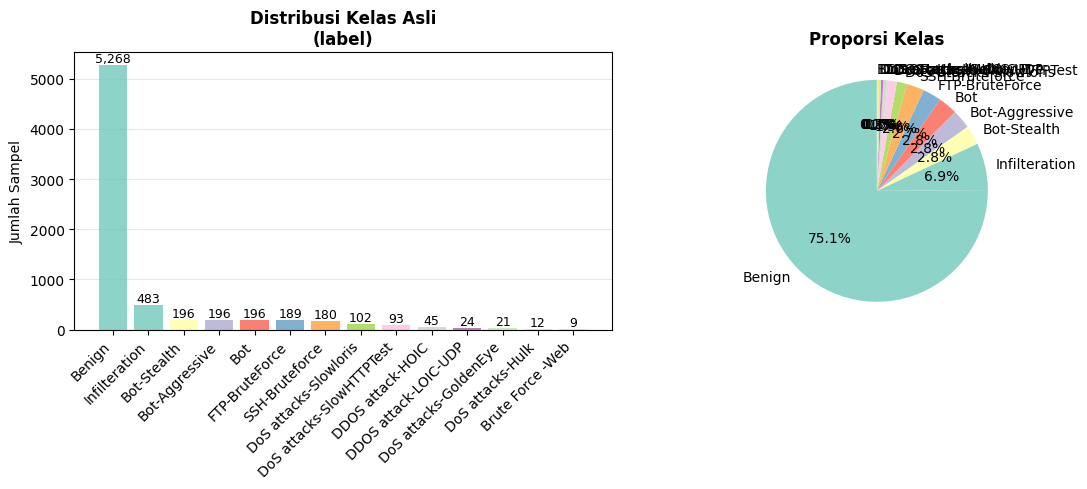


📊 Distribusi kelas:
label
Benign                      5268
Infilteration                483
Bot-Stealth                  196
Bot-Aggressive               196
Bot                          196
FTP-BruteForce               189
SSH-Bruteforce               180
DoS attacks-Slowloris        102
DoS attacks-SlowHTTPTest      93
DDOS attack-HOIC              45
DDOS attack-LOIC-UDP          24
DoS attacks-GoldenEye         21
DoS attacks-Hulk              12
Brute Force -Web               9


In [6]:
# ============================================
# VISUALISASI DISTRIBUSI KELAS
# ============================================
plt.figure(figsize=(12, 5))

# Plot 1: Distribusi kelas asli
plt.subplot(1, 2, 1)
class_counts = df[LABEL_COLUMN].value_counts()
colors = plt.cm.Set3(np.linspace(0, 1, len(class_counts)))
bars = plt.bar(range(len(class_counts)), class_counts.values, color=colors)
plt.xticks(range(len(class_counts)), class_counts.index, rotation=45, ha='right')
plt.title(f'Distribusi Kelas Asli\n({LABEL_COLUMN})', fontsize=12, fontweight='bold')
plt.ylabel('Jumlah Sampel')
plt.grid(axis='y', alpha=0.3)

# Tambahkan label nilai
for bar, val in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{val:,}', ha='center', va='bottom', fontsize=9)

# Plot 2: Pie chart
plt.subplot(1, 2, 2)
plt.pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
        colors=colors, startangle=90)
plt.title('Proporsi Kelas', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\n📊 Distribusi kelas:")
print(class_counts.to_string())

In [7]:
# ============================================
# BINARISASI LABEL (Benign vs Attack)
# ============================================
# Dataset HQC-2026 memiliki 7 kategori serangan + Benign
# Kita ubah menjadi klasifikasi biner untuk demo VQC

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df[LABEL_COLUMN])

print("Mapping label:")
for i, name in enumerate(label_encoder.classes_):
    print(f"   {i} → {name}")

# Tentukan indeks label 'Benign' / 'Normal'
# Cari nama yang mengandung 'benign', 'normal', atau '0'
benign_keywords = ['benign', 'normal', '0', 'safe']
benign_idx = None
for i, name in enumerate(label_encoder.classes_):
    if any(kw in str(name).lower() for kw in benign_keywords):
        benign_idx = i
        break

if benign_idx is None:
    benign_idx = 0
    print(f"\n⚠️  Tidak ditemukan label 'benign/normal', gunakan indeks 0: {label_encoder.classes_[0]}")

print(f"\n✅ Benign index: {benign_idx} → '{label_encoder.classes_[benign_idx]}'")

# Binarisasi: 0 = Benign, 1 = Attack
y = (y_encoded != benign_idx).astype(int)

print(f"\n📊 Distribusi label biner:")
print(f"   Benign (0): {sum(y == 0):,} ({sum(y == 0)/len(y)*100:.1f}%)")
print(f"   Attack (1): {sum(y == 1):,} ({sum(y == 1)/len(y)*100:.1f}%)")

Mapping label:
   0 → Benign
   1 → Bot
   2 → Bot-Aggressive
   3 → Bot-Stealth
   4 → Brute Force -Web
   5 → DDOS attack-HOIC
   6 → DDOS attack-LOIC-UDP
   7 → DoS attacks-GoldenEye
   8 → DoS attacks-Hulk
   9 → DoS attacks-SlowHTTPTest
   10 → DoS attacks-Slowloris
   11 → FTP-BruteForce
   12 → Infilteration
   13 → SSH-Bruteforce

✅ Benign index: 0 → 'Benign'

📊 Distribusi label biner:
   Benign (0): 5,268 (75.1%)
   Attack (1): 1,746 (24.9%)


In [8]:
# ============================================
# PISAHKAN FITUR DAN LABEL
# ============================================
# Buang kolom label dan kolom non-numerik
feature_cols = [col for col in df.columns if col != LABEL_COLUMN]
X_df = df[feature_cols].copy()

# Handle kolom kategorikal (one-hot atau drop)
categorical_features = X_df.select_dtypes(include=['object', 'category']).columns.tolist()

if categorical_features:
    print(f"⚠️  Ditemukan {len(categorical_features)} kolom kategorikal:")
    for col in categorical_features:
        print(f"   - {col}")
    
    # Drop kolom kategorikal (untuk demo sederhana)
    X_df = X_df.drop(columns=categorical_features)
    print(f"\n✅ Kolom kategorikal di-drop")

# Handle missing values
if X_df.isnull().sum().sum() > 0:
    print(f"\n⚠️  Ada missing values, mengisi dengan median...")
    X_df = X_df.fillna(X_df.median())

X_raw = X_df.values.astype(np.float32)

print(f"\n📊 Shape fitur: {X_raw.shape}")
print(f"📊 Shape label: {y.shape}")
print(f"📊 Tipe data  : {X_raw.dtype}")


⚠️  Ada missing values, mengisi dengan median...

📊 Shape fitur: (7014, 103)
📊 Shape label: (7014,)
📊 Tipe data  : float32


Reduksi dimensi: 103 fitur → 4 fitur (untuk 4 qubit)

✅ Explained variance ratio per komponen:
   PC1: 0.6426 (64.26%)
   PC2: 0.2070 (20.70%)
   PC3: 0.0528 (5.28%)
   PC4: 0.0349 (3.49%)

   Total: 0.9372 (93.72%)


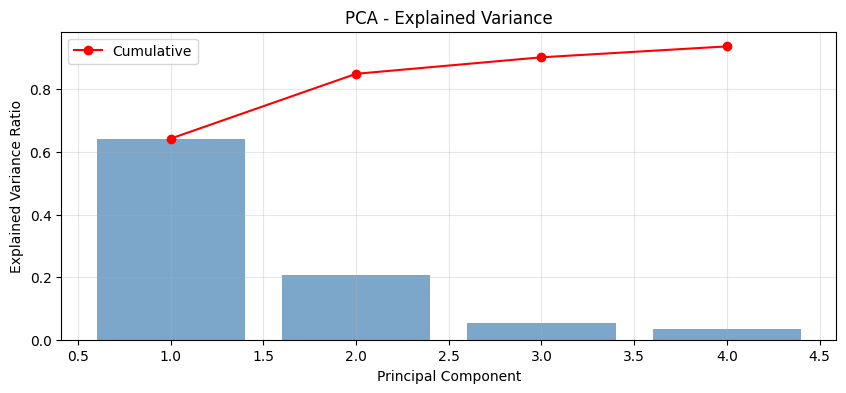

In [9]:
# ============================================
# REDUKSI DIMENSI: PCA
# ============================================
# VQC hanya bisa handle 4-10 qubit, jadi kita reduksi fitur
N_QUBITS = 4

print(f"Reduksi dimensi: {X_raw.shape[1]} fitur → {N_QUBITS} fitur (untuk {N_QUBITS} qubit)")

pca = PCA(n_components=N_QUBITS, random_state=42)
X_reduced = pca.fit_transform(X_raw)

print(f"\n✅ Explained variance ratio per komponen:")
for i, var in enumerate(pca.explained_variance_ratio_, 1):
    print(f"   PC{i}: {var:.4f} ({var*100:.2f}%)")
print(f"\n   Total: {pca.explained_variance_ratio_.sum():.4f} ({pca.explained_variance_ratio_.sum()*100:.2f}%)")

# Visualisasi
plt.figure(figsize=(10, 4))
plt.bar(range(1, N_QUBITS+1), pca.explained_variance_ratio_, alpha=0.7, color='steelblue')
plt.plot(range(1, N_QUBITS+1), np.cumsum(pca.explained_variance_ratio_), 
         'ro-', label='Cumulative')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA - Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('pca_variance.png', dpi=100, bbox_inches='tight')
plt.show()

📊 Training set: (4909, 4)
📊 Test set    : (2105, 4)

📊 Distribusi train:
   Benign: 3687, Attack: 1222

📊 Distribusi test:
   Benign: 1581, Attack: 524


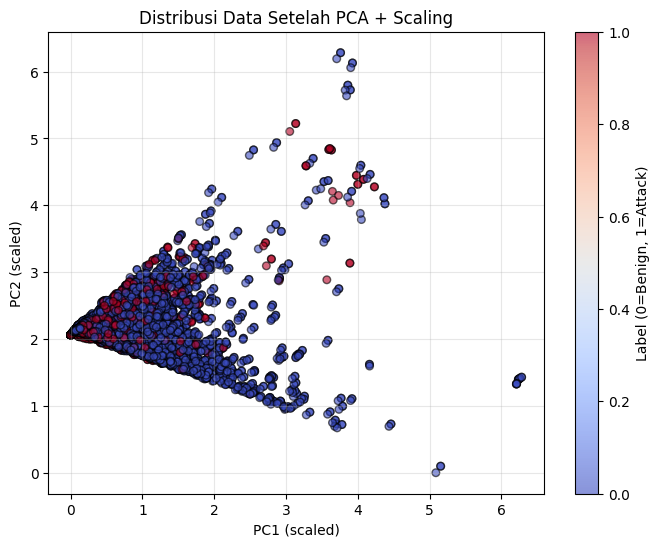

In [10]:
# ============================================
# NORMALISASI & SPLIT DATA
# ============================================
# Normalisasi ke range [0, 2π] untuk encoding sudut (angle encoding)
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
X_scaled = scaler.fit_transform(X_reduced)

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print(f"📊 Training set: {X_train.shape}")
print(f"📊 Test set    : {X_test.shape}")
print(f"\n📊 Distribusi train:")
print(f"   Benign: {sum(y_train == 0)}, Attack: {sum(y_train == 1)}")
print(f"\n📊 Distribusi test:")
print(f"   Benign: {sum(y_test == 0)}, Attack: {sum(y_test == 1)}")

# Visualisasi data setelah PCA (2D projection)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, 
                     cmap='coolwarm', alpha=0.6, edgecolors='k', s=30)
plt.colorbar(scatter, label='Label (0=Benign, 1=Attack)')
plt.xlabel('PC1 (scaled)')
plt.ylabel('PC2 (scaled)')
plt.title('Distribusi Data Setelah PCA + Scaling')
plt.grid(alpha=0.3)
plt.savefig('pca_2d_projection.png', dpi=100, bbox_inches='tight')
plt.show()

In [11]:
# ============================================
# BANGUN VQC (Variational Quantum Classifier)
# ============================================
print("=" * 60)
print("MEMBANGUN VQC")
print("=" * 60)

# Feature map: encode data klasik ke quantum state
feature_map = ZZFeatureMap(
    feature_dimension=N_QUBITS,
    reps=2,
    entanglement='linear'
)
print(f"\n✅ Feature Map: ZZFeatureMap")
print(f"   Qubit: {N_QUBITS}, Reps: 2")

# Ansatz: parameterized circuit yang akan dioptimasi
ansatz = RealAmplitudes(
    num_qubits=N_QUBITS,
    reps=3,
    entanglement='linear'
)
print(f"\n✅ Ansatz: RealAmplitudes")
print(f"   Qubit: {N_QUBITS}, Reps: 3")
print(f"   Jumlah parameter: {ansatz.num_parameters}")

# Optimizer
optimizer = COBYLA(maxiter=100)
print(f"\n✅ Optimizer: COBYLA (maxiter=100)")

# Sampler
sampler = StatevectorSampler()
print(f"✅ Sampler: StatevectorSampler")

MEMBANGUN VQC

✅ Feature Map: ZZFeatureMap
   Qubit: 4, Reps: 2

✅ Ansatz: RealAmplitudes
   Qubit: 4, Reps: 3
   Jumlah parameter: 16

✅ Optimizer: COBYLA (maxiter=100)
✅ Sampler: StatevectorSampler


In [12]:
# ============================================
# TRAINING VQC
# ============================================
import time

# Build VQC
vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=optimizer,
    sampler=sampler
)

print("🚀 Memulai training VQC...")
print("   (Ini mungkin memakan waktu beberapa menit)\n")

start_time = time.time()
vqc.fit(X_train, y_train)
training_time = time.time() - start_time

print(f"\n✅ Training selesai dalam {training_time:.2f} detik")

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


🚀 Memulai training VQC...
   (Ini mungkin memakan waktu beberapa menit)


✅ Training selesai dalam 10272.01 detik


HASIL EVALUASI VQC

🎯 Accuracy: 0.7126 (71.26%)

📋 Classification Report:
              precision    recall  f1-score   support

      Benign     0.7615    0.8988    0.8245      1581
      Attack     0.3305    0.1508    0.2071       524

    accuracy                         0.7126      2105
   macro avg     0.5460    0.5248    0.5158      2105
weighted avg     0.6542    0.7126    0.6708      2105



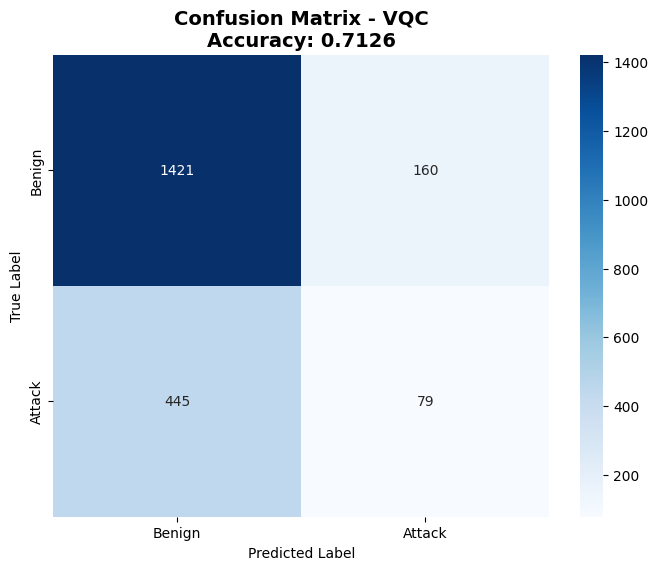

In [13]:
# ============================================
# EVALUASI VQC
# ============================================
# Prediksi
y_pred = vqc.predict(X_test)

# Metrik
accuracy = accuracy_score(y_test, y_pred)

print("=" * 60)
print("HASIL EVALUASI VQC")
print("=" * 60)
print(f"\n🎯 Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

print(f"\n📋 Classification Report:")
print(classification_report(y_test, y_pred, 
                          target_names=['Benign', 'Attack'],
                          digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Attack'],
            yticklabels=['Benign', 'Attack'])
plt.title(f'Confusion Matrix - VQC\nAccuracy: {accuracy:.4f}', 
         fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig('confusion_matrix_vqc.png', dpi=100, bbox_inches='tight')
plt.show()

PERBANDINGAN: QUANTUM vs CLASSICAL

🔄 Training Logistic Regression...
   ✅ Accuracy: 0.7853

🔄 Training SVM (RBF)...
   ✅ Accuracy: 0.7886

🔄 Training Random Forest...
   ✅ Accuracy: 0.8950


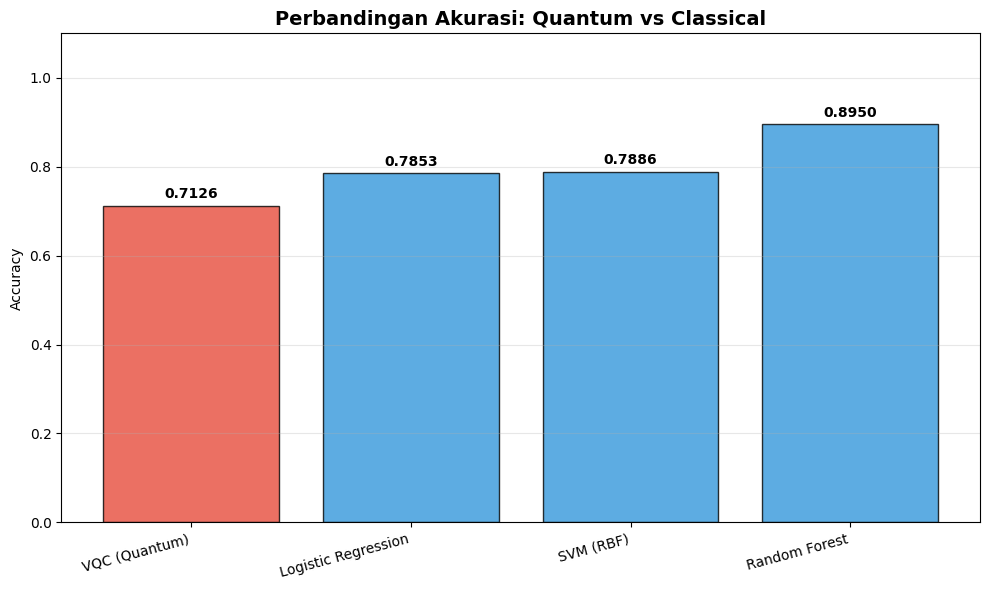


RINGKASAN HASIL
🥇 Random Forest            : 0.8950
   SVM (RBF)                : 0.7886
   Logistic Regression      : 0.7853
   VQC (Quantum)            : 0.7126


In [14]:
# ============================================
# PERBANDINGAN DENGAN CLASSICAL ML
# ============================================
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

print("=" * 60)
print("PERBANDINGAN: QUANTUM vs CLASSICAL")
print("=" * 60)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

results = {'VQC (Quantum)': accuracy}

for name, model in models.items():
    print(f"\n🔄 Training {name}...")
    model.fit(X_train, y_train)
    y_pred_clf = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred_clf)
    results[name] = acc
    print(f"   ✅ Accuracy: {acc:.4f}")

# Visualisasi perbandingan
plt.figure(figsize=(10, 6))
names = list(results.keys())
accs = list(results.values())
colors = ['#e74c3c' if 'Quantum' in n else '#3498db' for n in names]
bars = plt.bar(names, accs, color=colors, alpha=0.8, edgecolor='black')

for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.4f}', ha='center', va='bottom', fontweight='bold')

plt.ylim(0, 1.1)
plt.ylabel('Accuracy')
plt.title('Perbandingan Akurasi: Quantum vs Classical', fontsize=14, fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('comparison_quantum_classical.png', dpi=100, bbox_inches='tight')
plt.show()

print("\n" + "=" * 60)
print("RINGKASAN HASIL")
print("=" * 60)
for name, acc in sorted(results.items(), key=lambda x: -x[1]):
    marker = "🥇" if acc == max(results.values()) else "  "
    print(f"{marker} {name:25s}: {acc:.4f}")

In [16]:
import pickle
import json
from datetime import datetime
from qiskit_machine_learning.algorithms import VQC

# Buat folder output
os.makedirs('outputs', exist_ok=True)
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

# ============================================
# SIMPAN MODEL VQC (Gunakan .save() bawaan)
# ============================================
model_path = f'outputs/vqc_model_{timestamp}.model'
vqc.save(model_path)
print(f"✅ Model VQC disimpan: {model_path}")

# Simpan preprocessing (scaler, pca, label_encoder) dengan pickle — ini aman karena objek sklearn standar
preprocessing_path = f'outputs/preprocessing_{timestamp}.pkl'
with open(preprocessing_path, 'wb') as f:
    pickle.dump({'scaler': scaler, 'pca': pca, 'label_encoder': label_encoder}, f)
print(f"✅ Preprocessing pipeline disimpan: {preprocessing_path}")

# Simpan hasil metrik
metrics = {
    'timestamp': timestamp,
    'dataset': 'HQC-2026 (Parquet)',
    'n_qubits': N_QUBITS,
    'n_train': len(X_train),
    'n_test': len(X_test),
    'accuracy': float(accuracy),
    'training_time_seconds': float(training_time),
    'results_comparison': {k: float(v) for k, v in results.items()}
}

metrics_path = f'outputs/metrics_{timestamp}.json'
with open(metrics_path, 'w') as f:
    json.dump(metrics, f, indent=2)
print(f"✅ Metrics disimpan: {metrics_path}")

print("\n🎉 Demo selesai!")

✅ Model VQC disimpan: outputs/vqc_model_20261014_024053.model
✅ Preprocessing pipeline disimpan: outputs/preprocessing_20261014_024053.pkl
✅ Metrics disimpan: outputs/metrics_20261014_024053.json

🎉 Demo selesai!


In [17]:
from qiskit_machine_learning.algorithms import VQC
from qiskit.primitives import StatevectorSampler

# Load model yang sudah disimpan
loaded_vqc = VQC.load('outputs/vqc_model_20261014_024053.model')

# Untuk inference, pastikan sampler sudah di-set (jika perlu)
loaded_vqc.neural_network.sampler = StatevectorSampler()

# Prediksi
y_pred_loaded = loaded_vqc.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_loaded):.4f}")

Accuracy: 0.7173
